# 07 — Final Model Evaluation

## Objective

This notebook performs the final evaluation of the selected customer churn model on the held-out test set.

All model-selection decisions have already been made using training data:

- model family: Gradient Boosting;
- hyperparameters selected through stratified cross-validation;
- classification threshold selected using out-of-fold training predictions.

The test set is now used once to estimate final generalization performance.

No model, hyperparameter or threshold changes will be made based on the results observed in this notebook.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

In [2]:
PROJECT_ROOT = Path("..")

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "WA_FnUseC_TelcoCustomerChurn.csv"
)

df = pd.read_csv(DATA_PATH)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape

((5634, 19), (1409, 19))

In [3]:
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    column
    for column in X_train.columns
    if column not in numeric_features
]

In [4]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

## Final Model

The final model configuration was selected before accessing test performance.

The selected classifier is Gradient Boosting with 300 estimators, a learning rate of 0.1, maximum tree depth of 1 and minimum leaf size of 1.

The classification threshold is fixed at 0.35.

In [5]:
FINAL_THRESHOLD = 0.35

final_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            GradientBoostingClassifier(
                n_estimators=300,
                learning_rate=0.1,
                max_depth=1,
                min_samples_leaf=1,
                random_state=42
            )
        )
    ]
)

In [6]:
final_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``

In [7]:
class_labels = list(
    final_model.named_steps["classifier"].classes_
)

class_labels

['No', 'Yes']

In [8]:
positive_class_index = class_labels.index("Yes")

test_probabilities = final_model.predict_proba(
    X_test
)[:, positive_class_index]

In [9]:
test_predictions = np.where(
    test_probabilities >= FINAL_THRESHOLD,
    "Yes",
    "No"
)

In [10]:
final_model.predict(X_test)

array(['No', 'Yes', 'No', ..., 'No', 'No', 'No'],
      shape=(1409,), dtype=object)

In [11]:
final_accuracy = accuracy_score(
    y_test,
    test_predictions
)

final_precision = precision_score(
    y_test,
    test_predictions,
    pos_label="Yes",
    zero_division=0
)

final_recall = recall_score(
    y_test,
    test_predictions,
    pos_label="Yes",
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    test_predictions,
    pos_label="Yes",
    zero_division=0
)

final_roc_auc = roc_auc_score(
    y_test,
    test_probabilities
)

final_average_precision = average_precision_score(
    y_test == "Yes",
    test_probabilities
)

In [12]:
final_metrics = pd.DataFrame({
    "metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "Average Precision"
    ],
    "value": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1,
        final_roc_auc,
        final_average_precision
    ]
})

final_metrics.round(4)

,metric,value
0,Accuracy,0.7757
1,Precision,0.5602
2,Recall,0.7219
3,F1-score,0.6308
4,ROC-AUC,0.8467
5,Average Precision,0.6675


In [13]:
final_confusion_matrix = confusion_matrix(
    y_test,
    test_predictions,
    labels=["No", "Yes"]
)

final_confusion_matrix

array([[823, 212],
       [104, 270]])

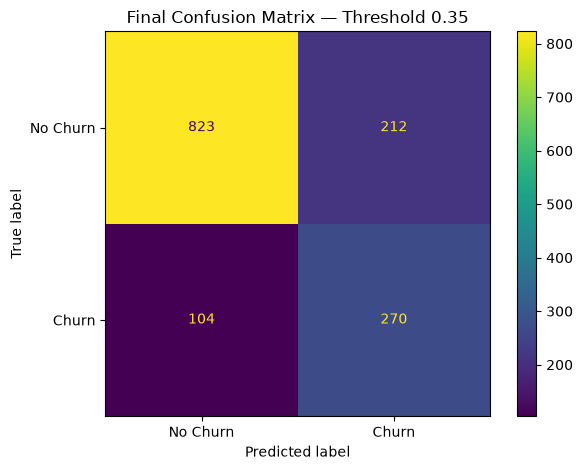

In [14]:
ConfusionMatrixDisplay(
    confusion_matrix=final_confusion_matrix,
    display_labels=["No Churn", "Churn"]
).plot()

plt.title(
    f"Final Confusion Matrix — Threshold {FINAL_THRESHOLD}"
)

plt.tight_layout()
plt.show()

In [15]:
print(
    classification_report(
        y_test,
        test_predictions,
        labels=["No", "Yes"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

          No       0.89      0.80      0.84      1035
         Yes       0.56      0.72      0.63       374

    accuracy                           0.78      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.78      0.78      1409



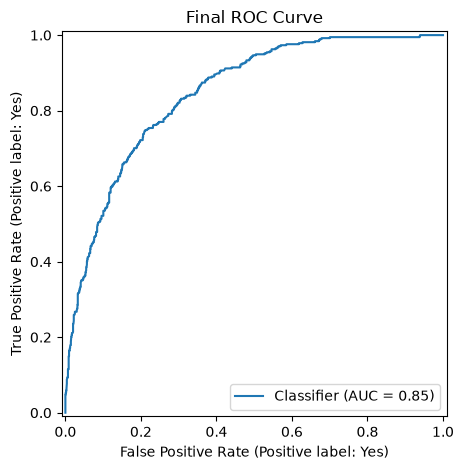

In [16]:
RocCurveDisplay.from_predictions(
    y_test,
    test_probabilities,
    pos_label="Yes"
)

plt.title("Final ROC Curve")
plt.tight_layout()
plt.show()

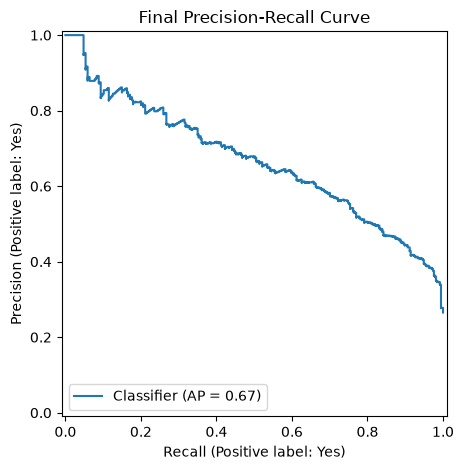

In [17]:
PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities,
    pos_label="Yes"
)

plt.title("Final Precision-Recall Curve")
plt.tight_layout()
plt.show()

In [18]:
default_predictions = np.where(
    test_probabilities >= 0.50,
    "Yes",
    "No"
)

threshold_test_comparison = pd.DataFrame({
    "threshold": [
        0.35,
        0.50
    ],
    "precision": [
        precision_score(
            y_test,
            test_predictions,
            pos_label="Yes"
        ),
        precision_score(
            y_test,
            default_predictions,
            pos_label="Yes"
        )
    ],
    "recall": [
        recall_score(
            y_test,
            test_predictions,
            pos_label="Yes"
        ),
        recall_score(
            y_test,
            default_predictions,
            pos_label="Yes"
        )
    ],
    "f1": [
        f1_score(
            y_test,
            test_predictions,
            pos_label="Yes"
        ),
        f1_score(
            y_test,
            default_predictions,
            pos_label="Yes"
        )
    ]
})

threshold_test_comparison.round(4)

,threshold,precision,recall,f1
0,0.35,0.5602,0.7219,0.6308
1,0.50,0.6644,0.5134,0.5792


In [19]:
final_metrics.round(4)

,metric,value
0,Accuracy,0.7757
1,Precision,0.5602
2,Recall,0.7219
3,F1-score,0.6308
4,ROC-AUC,0.8467
5,Average Precision,0.6675


In [20]:
final_confusion_matrix

array([[823, 212],
       [104, 270]])

In [21]:
default_predictions = np.where(
    test_probabilities >= 0.50,
    "Yes",
    "No"
)

threshold_test_comparison = pd.DataFrame({
    "threshold": [
        0.35,
        0.50
    ],
    "accuracy": [
        accuracy_score(
            y_test,
            test_predictions
        ),
        accuracy_score(
            y_test,
            default_predictions
        )
    ],
    "precision": [
        precision_score(
            y_test,
            test_predictions,
            pos_label="Yes"
        ),
        precision_score(
            y_test,
            default_predictions,
            pos_label="Yes"
        )
    ],
    "recall": [
        recall_score(
            y_test,
            test_predictions,
            pos_label="Yes"
        ),
        recall_score(
            y_test,
            default_predictions,
            pos_label="Yes"
        )
    ],
    "f1": [
        f1_score(
            y_test,
            test_predictions,
            pos_label="Yes"
        ),
        f1_score(
            y_test,
            default_predictions,
            pos_label="Yes"
        )
    ]
})

threshold_test_comparison.round(4)

,threshold,accuracy,precision,recall,f1
0,0.35,0.7757,0.5602,0.7219,0.6308
1,0.50,0.8020,0.6644,0.5134,0.5792


In [22]:
default_confusion_matrix = confusion_matrix(
    y_test,
    default_predictions,
    labels=["No", "Yes"]
)

print("Selected threshold (0.35):")
print(final_confusion_matrix)

print("\nDefault threshold (0.50):")
print(default_confusion_matrix)

Selected threshold (0.35):
[[823 212]
 [104 270]]

Default threshold (0.50):
[[938  97]
 [182 192]]


## Final Evaluation Interpretation

The final Gradient Boosting model achieves a test ROC-AUC of approximately **0.847**, closely matching the cross-validated ROC-AUC obtained during model development.

This small difference between cross-validation and held-out test performance suggests that the model generalizes consistently to unseen customers.

Using the pre-selected classification threshold of **0.35**, the model achieves:

- approximately **72% recall** for churn;
- approximately **56% precision**;
- an F1-score of approximately **0.63**.

The final confusion matrix shows that 270 of the 374 churned customers in the held-out test set are correctly identified, while 104 churners remain undetected.

The selected threshold intentionally prioritizes churn detection over overall accuracy and precision. This behavior is consistent with the threshold strategy established before accessing test performance.

The test results are reported as the final estimate of model generalization. No additional hyperparameter or threshold optimization is performed after observing these results.

In [23]:
cv_roc_auc = 0.8509461720524779

generalization_summary = pd.DataFrame({
    "evaluation": [
        "Cross-validation",
        "Held-out test"
    ],
    "roc_auc": [
        cv_roc_auc,
        final_roc_auc
    ]
})

generalization_summary["difference_from_cv"] = (
    generalization_summary["roc_auc"]
    - cv_roc_auc
)

generalization_summary.round(4)

,evaluation,roc_auc,difference_from_cv
0,Cross-validation,0.8509,0.0000
1,Held-out test,0.8467,-0.0043


In [24]:
threshold_test_comparison.round(4)

,threshold,accuracy,precision,recall,f1
0,0.35,0.7757,0.5602,0.7219,0.6308
1,0.50,0.8020,0.6644,0.5134,0.5792


## Threshold Comparison on the Test Set

The pre-selected threshold of 0.35 behaves consistently with the trade-off observed during training.

Compared with the default threshold of 0.50:

- recall increases substantially, from approximately 51% to 72%;
- F1-score improves from approximately 0.58 to 0.63;
- precision decreases from approximately 66% to 56%;
- overall accuracy decreases slightly.

This confirms that the selected operating point prioritizes churn detection over conservative classification.

Importantly, the 0.35 threshold was selected before accessing the held-out test set. The test comparison is reported only to describe final model behavior and is not used to modify the threshold.

## Final Conclusions

The final Gradient Boosting model achieves a held-out test ROC-AUC of approximately 0.847, closely matching the cross-validated ROC-AUC of approximately 0.851 observed during model development.

This small generalization gap indicates that the model performs consistently on unseen customers.

Using the fixed classification threshold of 0.35, the final system achieves approximately:

- 77.6% accuracy;
- 56.0% precision;
- 72.2% recall;
- 0.631 F1-score;
- 0.847 ROC-AUC;
- 0.668 average precision.

The model correctly identifies 270 of the 374 churned customers in the held-out test set.

No further model, hyperparameter or threshold optimization is performed after observing test performance. These results are treated as the final unbiased estimate of the selected model's predictive performance.